# 10 · Markups and concentration: are a few firms taking a growing share of profits?
Two measures, both on listed non-financial firms:
* **Markup proxy:** sales divided by cost of goods sold. De Loecker, Eeckhout & Unger (2020) multiply this ratio by an output elasticity. With a constant elasticity, its trend and its sales-weighted average carry the same information.
* **Concentration:** within each country, industry group and year with at least 20 listed firms, the share of sales earned by the four largest firms (CR4) and the share of operating profit earned by the top 10% of firms by sales.

Listed firms are a subset of each economy, so concentration here is concentration **among listed companies**.

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")
IG = {"1010": "Energy", "1510": "Materials", "2010": "Capital goods", "2020": "Commercial & professional services", "2030": "Transportation",
      "2510": "Autos & components", "2520": "Consumer durables & apparel", "2530": "Consumer services", "2540": "Media & entertainment",
      "2550": "Retail", "3010": "Food & staples retail", "3020": "Food, beverage & tobacco", "3030": "Household & personal products",
      "3510": "Health care equipment & services", "3520": "Pharma & biotech", "4510": "Software & IT services", "4520": "Technology hardware",
      "4530": "Semiconductors", "5010": "Telecom services", "5020": "Media & entertainment", "6010": "Real estate"}
MODEL = {"Consumer services": "Paid in advance", "Telecom services": "Paid in advance", "Media & entertainment": "Paid in advance",
         "Software & IT services": "Asset-light, invoiced", "Commercial & professional services": "Asset-light, invoiced", "Transportation": "Asset-light, invoiced",
         "Retail": "Paid at the till", "Food & staples retail": "Paid at the till",
         "Energy": "Resources", "Materials": "Resources",
         "Capital goods": "Goods producers", "Autos & components": "Goods producers", "Consumer durables & apparel": "Goods producers",
         "Food, beverage & tobacco": "Goods producers", "Household & personal products": "Goods producers", "Technology hardware": "Goods producers",
         "Semiconductors": "Goods producers", "Health care equipment & services": "Health care", "Pharma & biotech": "Health care", "Real estate": "Real estate"}
p["industry"] = p["industry_group"].map(IG); p["model"] = p["industry"].map(MODEL)
p["no_inventory"] = (p["dio"] < 3.65).astype(float).where(p["dio"].notna())        # inventory below 1% of a year's cost of sales; firms that report inventory
p["negative_cycle"] = (p["ccc"] < 0).astype(float).where(p["ccc"].notna())
# raw statement items, same rows and order as the panel (scripts/build_panel.py); private, never published
r = pd.read_parquet(PANEL.with_name("panel_raw.parquet"))
assert (r[["gvkey", "fyear"]].to_numpy() == p[["gvkey", "fyear"]].to_numpy()).all()
p = pd.concat([p, r.drop(columns=["gvkey", "fyear"]).add_prefix("x_")], axis=1)
def wins(s, by=None, lo=0.01, hi=0.99):
    s = s.replace([np.inf, -np.inf], np.nan); by = p.loc[s.index, "fyear"] if by is None else by
    return s.clip(s.groupby(by).transform(lambda v: v.quantile(lo)), s.groupby(by).transform(lambda v: v.quantile(hi)), axis=0)
p = p.sort_values(["gvkey", "fyear"]).reset_index(drop=True)
def lag(col, k=1):
    g = p.groupby("gvkey"); v = g[col].shift(k); gap = p["fyear"] - g["fyear"].shift(k)
    return v.where(gap == k)
def lead(col, k=1):
    g = p.groupby("gvkey"); v = g[col].shift(-k); gap = g["fyear"].shift(-k) - p["fyear"]
    return v.where(gap == k)
p["markup"] = wins(p.x_sale / p.x_cogs.where(p.x_cogs > 0))
p["sale_w"] = p.sale_usd.where(p.sale_usd > 0)
def wmean(d, col, wcol="sale_w"):
    d = d.dropna(subset=[col, wcol]); return np.average(d[col], weights=d[wcol]) if len(d) else np.nan
print(f"markup available for {p.markup.notna().mean():.0%} of firm-years")

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


markup available for 96% of firm-years


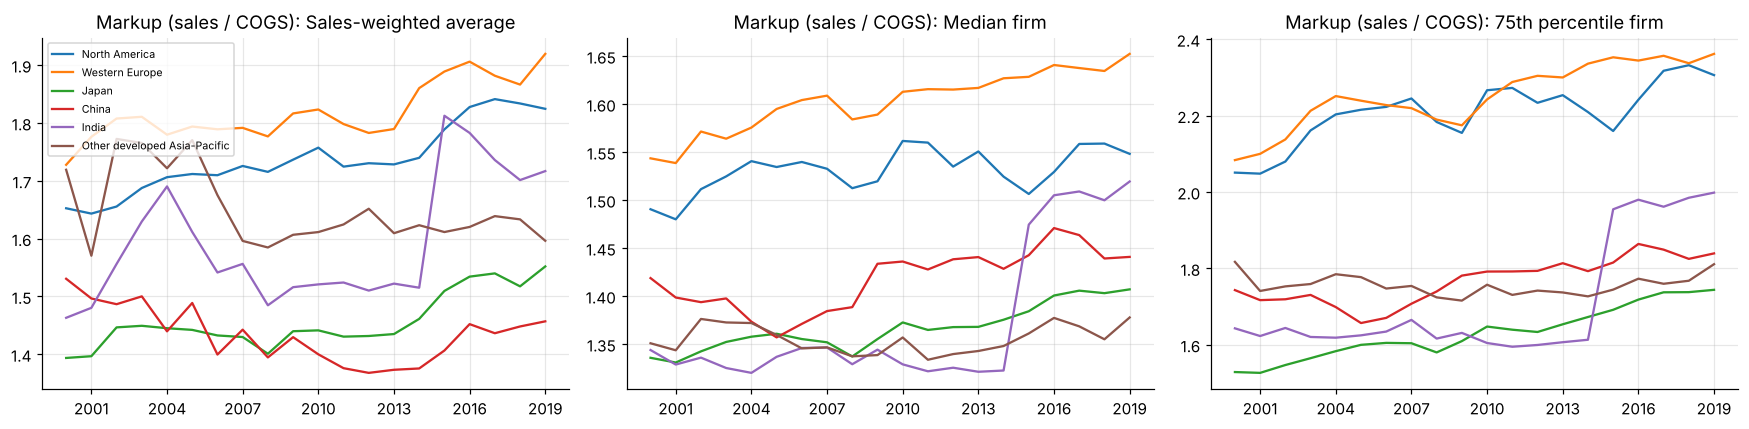

Trend charts stop at 2019: fiscal 2020 was incomplete when the data was extracted.


,weighted change 2000-2019,median change 2000-2019,p75 change 2000-2019
region,,,
North America,0.17,0.06,0.26
Western Europe,0.19,0.11,0.28
Japan,0.16,0.07,0.22
China,-0.07,0.02,0.10
India,0.25,0.18,0.36
Other developed Asia-Pacific,-0.12,0.03,-0.01


In [2]:
REG5 = ["North America", "Western Europe", "Japan", "China", "India", "Other developed Asia-Pacific"]
mk = p[p.region.isin(REG5) & p.fyear.le(2019)].groupby(["fyear", "region"]).apply(lambda d: pd.Series({"weighted": wmean(d, "markup"), "median": d.markup.median(),
                                                                                      "p75": d.markup.quantile(0.75)})).unstack()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c, t in zip(ax, ["weighted", "median", "p75"], ["Sales-weighted average", "Median firm", "75th percentile firm"]):
    mk[c][REG5].plot(ax=a, legend=a is ax[0]); a.set_title(f"Markup (sales / COGS): {t}"); int_years(a)
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(IMG / "markups_trends.png", bbox_inches="tight"); plt.show()
chg = pd.DataFrame({c: mk[c].loc[2019] - mk[c].loc[2000] for c in ["weighted", "median", "p75"]}).reindex(REG5)
print("Trend charts stop at 2019: fiscal 2020 was incomplete when the data was extracted.")
mk_out = pd.concat({"2000": mk.loc[2000].unstack(0), "2019": mk.loc[2019].unstack(0)}, axis=1); mk_out.to_csv(DATA / "markups_2000_2019.csv")
chg.rename(columns=lambda c: c + " change 2000-2019").style.format(precision=2)

The rise in the weighted average can come from firms raising markups (**within**) or from sales moving to high-markup firms (**reallocation**). A simple split for North America compares the change holding 2000 weights with the change in weights.

In [3]:
def decompose(reg_, y0=2000, y1=2019):
    d = p[p.region.eq(reg_) & p.fyear.isin([y0, y1])].dropna(subset=["markup", "sale_w"])
    a, b = d[d.fyear.eq(y0)].set_index("gvkey"), d[d.fyear.eq(y1)].set_index("gvkey")
    both = a.index.intersection(b.index)
    wa = a.sale_w / a.sale_w.sum(); wb_ = b.sale_w / b.sale_w.sum()
    total = (wb_ * b.markup).sum() - (wa * a.markup).sum()
    wa_c, wb_c = wa[both] / wa[both].sum(), wb_[both] / wb_[both].sum()
    within = (wa_c * (b.markup[both] - a.markup[both])).sum()
    realloc = ((wb_c - wa_c) * b.markup[both]).sum()
    return pd.Series({"total change": total, "within continuing firms": within, "reallocation among continuing firms": realloc,
                      "entry and exit": total - within - realloc, "continuing firms": len(both)})
dec = pd.DataFrame({r_: decompose(r_) for r_ in REG5}).T; dec.to_csv(DATA / "markup_decomposition.csv")
dec["continuing firms"] = dec["continuing firms"].astype(int); dec.style.format(precision=3)

,total change,within continuing firms,reallocation among continuing firms,entry and exit,continuing firms
North America,0.172,0.075,0.019,0.078,1813
Western Europe,0.192,0.127,0.151,-0.087,735
Japan,0.158,0.104,0.031,0.023,1814
China,-0.074,-0.085,0.002,0.010,953
India,0.254,0.331,-0.160,0.083,1140
Other developed Asia-Pacific,-0.123,-0.130,0.077,-0.070,822


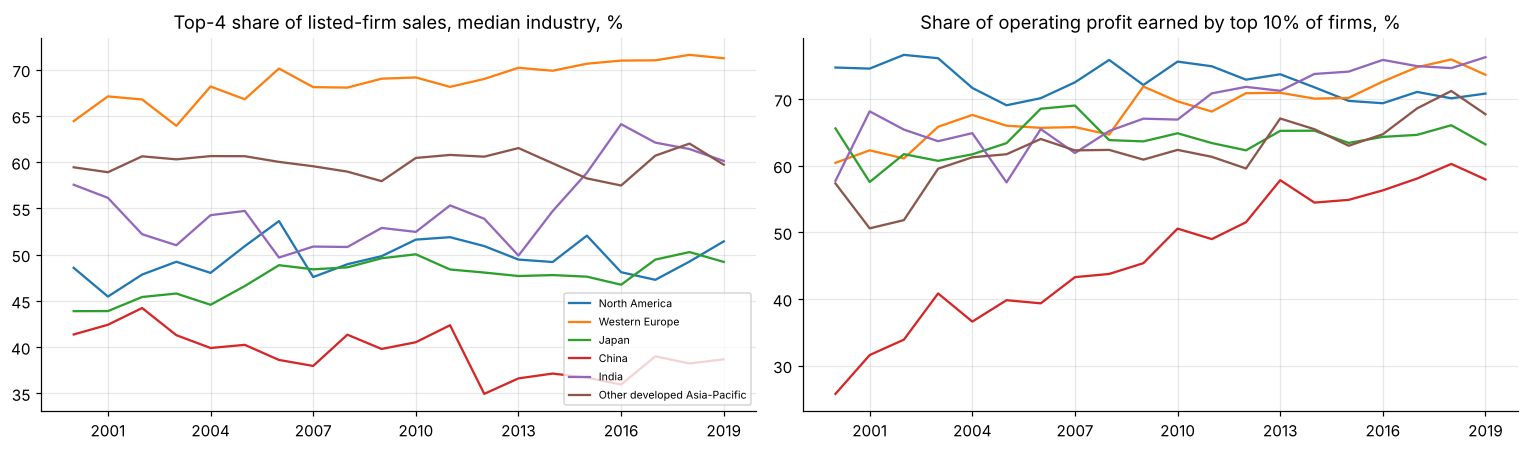

2005                     2019                   
                               cr4 top10_profit_share   cr4 top10_profit_share
region                                                                        
North America                 50.9               69.1  51.4               70.8
Western Europe                66.8               66.0  71.2               73.6
Japan                         46.6               63.4  49.2               63.2
China                         40.2               39.8  38.7               57.9
India                         54.7               57.5  60.1               76.3
Other developed Asia-Pacific  60.6               61.7  59.7               67.7

In [4]:
def conc(d):
    d = d.dropna(subset=["sale_w"]).sort_values("sale_w", ascending=False)
    if len(d) < 20: return None
    top10 = d.head(max(1, int(round(0.1 * len(d)))))
    op = d.x_oiadp / d.x_lcu_per_usd; pos = op.clip(lower=0)
    return pd.Series({"cr4": d.sale_w.head(4).sum() / d.sale_w.sum(),
                      "top10_profit_share": pos.loc[top10.index].sum() / pos.sum() if pos.sum() > 0 else np.nan, "n": len(d)})
cc = p.groupby(["loc", "industry_group", "fyear"]).apply(conc).dropna(how="all").reset_index()
cc["region"] = cc["loc"].map(p.groupby("loc").region.first())
trend = cc[cc.region.isin(REG5) & cc.fyear.le(2019)].groupby(["fyear", "region"])[["cr4", "top10_profit_share"]].median().unstack()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
(100 * trend["cr4"][REG5]).plot(ax=ax[0]); ax[0].set_title("Top-4 share of listed-firm sales, median industry, %"); int_years(ax[0]); ax[0].legend(fontsize=7)
(100 * trend["top10_profit_share"][REG5]).plot(ax=ax[1], legend=False); ax[1].set_title("Share of operating profit earned by top 10% of firms, %"); int_years(ax[1])
plt.tight_layout(); plt.savefig(IMG / "concentration_trends.png", bbox_inches="tight"); plt.show()
ctab = pd.concat({"2005": trend.loc[2005].unstack(0), "2019": trend.loc[2019].unstack(0)}, axis=1).reindex(REG5) * 100
ctab.to_csv(DATA / "concentration_by_region.csv"); ctab.round(1)

In [5]:
us = cc[cc["loc"].eq("USA")].assign(industry=lambda d: d.industry_group.map(IG))
usi = us[us.fyear.isin([2005, 2019])].pivot_table(index="industry", columns="fyear", values=["cr4", "top10_profit_share"]) * 100
usi = usi.dropna(); usi[("cr4", "change")] = usi[("cr4", 2019)] - usi[("cr4", 2005)]
usi = usi.sort_values(("cr4", "change")); usi.to_csv(DATA / "us_concentration_by_industry.csv"); usi.round(1)

cr4       top10_profit_share          cr4
fyear                               2005  2019               2005  2019 change
industry                                                                      
Real estate                         38.6  23.1               47.1  46.0  -15.5
Energy                              55.1  41.4               81.9  70.0  -13.8
Pharma & biotech                    50.8  44.1               97.1  97.7   -6.7
Capital goods                       29.1  23.0               82.6  67.0   -6.1
Household & personal products       74.5  69.5               90.2  82.0   -5.0
Software & IT services              45.8  41.7               89.1  88.7   -4.1
Autos & components                  80.4  76.6               71.3  69.3   -3.8
Materials                           19.9  18.5               53.2  45.2   -1.4
Commercial & professional services  23.4  23.2               58.8  47.7   -0.2
Transportation                      34.3  35.1               55.0  34.9    0.7
Food, beverage & tobacco            34.3  35.5               69.8  67.0    1.2
Consumer services                   24.0  25.5               64.1  64.6    1.5
Semiconductors                      45.9  51.4               81.6  82.1    5.6
Media & entertainment               46.9  54.0               69.6  85.0    7.1
Consumer durables & apparel         19.6  30.1               68.2  58.4   10.5
Retail                              29.4  42.2               66.9  69.1   12.9
Food & staples retail               60.6  74.5               72.2  70.8   13.9
Health care equipment & services    33.5  48.0               82.4  86.4   14.5
Technology hardware                 37.9  54.0               88.4  90.1   16.1
Telecom services                    56.8  88.6               88.9  91.8   31.8

In [6]:
# do concentrated industries earn higher markups? firm-level, country-industry-year concentration merged back
m = p.merge(cc[["loc", "industry_group", "fyear", "cr4"]], on=["loc", "industry_group", "fyear"], how="inner").dropna(subset=["markup", "cr4", "roa"])
m["cr4_q"] = pd.qcut(m.cr4, 5, labels=["lowest", "2", "3", "4", "highest"])
byq = m.groupby("cr4_q", observed=True).agg(cr4=("cr4", "median"), markup=("markup", "median"), roa=("roa", "median"), firms=("gvkey", "nunique"))
fe = regress.fe(m.assign(cr4_pct=m.cr4 * 100), "roa", ["cr4_pct", "size", "leverage"])
print(f"Firm and year FE: 10 points more top-4 concentration -> ROA {10 * fe.loc['cr4_pct', 'coef'] * 100:+.2f} points (t = {fe.loc['cr4_pct', 't']:.1f}; {fe.attrs['nobs']:,} obs)")
byq.round(3)

Firm and year FE: 10 points more top-4 concentration -> ROA +0.34 points (t = 4.5; 485,872 obs)


,cr4,markup,roa,firms
cr4_q,,,,
lowest,0.24,1.39,0.05,13323
2,0.34,1.37,0.05,17238
3,0.44,1.43,0.04,19913
4,0.54,1.46,0.05,19038
highest,0.74,1.46,0.04,13715


## Findings
* **Markups rose in most rich economies.** The sales-weighted ratio of sales to cost of goods sold rose from 1.65 to 1.83 in North America and from 1.73 to 1.92 in Western Europe (2000-2019), with similar rises in Japan and India. China's weighted markup fell slightly.
* **In North America the rise is spread out, not just superstar firms.** Of the +0.17 rise, +0.08 came from continuing firms raising markups and +0.08 from entry and exit (new high-markup firms replacing low-markup ones). Reallocation of sales towards high-markup continuing firms added only +0.02. In Western Europe, reallocation to high-markup firms was as large as the within-firm rise.
* **The typical US industry is no more concentrated among listed firms than in 2005** (median top-4 share about 51%), but some industries changed sharply: telecom services (+32 points, to 89%), technology hardware (+16), health care equipment and services (+15), food retail (+14) and retail (+13). Energy, real estate and capital goods became less concentrated.
* **Profits are far more concentrated than sales.** In the median industry, the top 10% of listed firms earn about 70% of operating profit in North America and 74-76% in Western Europe and India (2019). China's top-10% share rose from 40% to 58% between 2005 and 2019.
* **Concentration pays a little.** Within the same firm over time, a 10-point rise in its industry's top-4 share goes with 0.34 points higher ROA (t = 4.5). Firms in the most concentrated fifth of industries have a median markup of 1.46 vs 1.39 in the least concentrated.
* Caveat: Indian markups jump in fiscal 2015-2016, which coincides with changes in Compustat's Indian coverage and the move to Ind AS reporting. It should not be read as a real pricing change.